This time, I'm going to make another version of the decorrelation scale figure. My previous analysis showed that there are probably not a single decorrelation scale for all of the sampling points in the Seto Inland Sea. So the current hypothesis now is that the decorrelation scale is different for each of the sampling points. If this is true, this result may suggest that the effect of hypoxia is isolated in small regions. 

The first step is to find out what is the appropriate distance lag interval for the autocorrelation formula. We do this by calculating the average and median nearest neighbor distance in the dataset. This distance will serve as a proxy for the search radius in the autocorrelation formula.

In [2]:
import sys
from pathlib import Path

# Ensure local scripts are importable
project_root = Path("..").resolve()
sys.path.append(str(project_root))

from scripts.data_loader import load_and_process_data, load_raw_shapefiles
from utils.paths import ProjectPaths

print("Project Root:", project_root)

# Set force_reload=True if you added new raw data or changed the cleaning logic
merged_gdf = load_and_process_data(force_reload=True)

print("Data Shape:", merged_gdf.shape)
merged_gdf.info()

Project Root: C:\Users\reyha\Documents\SIS_Analysis
Loading raw shapefiles from 1981 to 2023...
Merging 84 shapefiles...
Processing data (cleaning DO, adding seasons)...
Saving processed data to C:\Users\reyha\Documents\SIS_Analysis\data\processed\merged_gdf.feather...
Data Shape: (41346, 65)
<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 41346 entries, 0 to 41345
Data columns (total 65 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   uniqueid        41346 non-null  object        
 1   zettaicode      41346 non-null  object        
 2   locationna      41346 non-null  object        
 3   wancode         41346 non-null  object        
 4   prefectuei      41346 non-null  object        
 5   watercode       41346 non-null  int32         
 6   renban          41346 non-null  object        
 7   nendo           41346 non-null  int64         
 8   survey_ym       41346 non-null  datetime64[ms]
 9   surveyyear  

In [3]:
import pandas as pd
from utils.paths import ProjectPaths

yearly_do_df = pd.read_csv(ProjectPaths.PROCESSED_DATA_DIR / 'yearly_do_df.csv')
yearly_do_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 127 entries, 0 to 126
Data columns (total 43 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  127 non-null    int64  
 1   1981        118 non-null    float64
 2   1982        124 non-null    float64
 3   1983        122 non-null    float64
 4   1984        124 non-null    float64
 5   1985        124 non-null    float64
 6   1986        124 non-null    float64
 7   1987        122 non-null    float64
 8   1988        124 non-null    float64
 9   1989        124 non-null    float64
 10  1990        124 non-null    float64
 11  1991        124 non-null    float64
 12  1992        123 non-null    float64
 13  1993        124 non-null    float64
 14  1994        122 non-null    float64
 15  1995        124 non-null    float64
 16  1996        124 non-null    float64
 17  1997        124 non-null    float64
 18  1998        123 non-null    float64
 19  1999        124 non-null    f

In [4]:
# Filter summer bottom do data
summer_bottom_df = merged_gdf[
    (merged_gdf['season'] == 'Summer') &
    (merged_gdf['saisuipoin'] == 2)
].dropna(subset=['do_']).copy()

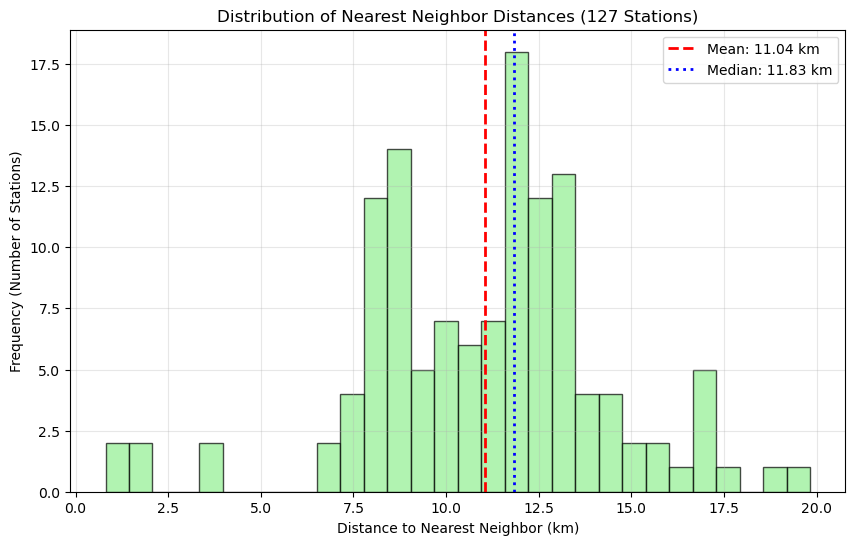

Nearest Neighbor Histogram saved as 'nearest_neighbor_histogram.png'.
Mean Nearest Neighbor Distance: 11.04 km
Median Nearest Neighbor Distance: 11.83 km
RECOMMENDATION: Set the Spatial Lag to approx 11 - 13 km


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist
import geopandas as gpd

# --- 1. Prepare Yearly DO Dataframe (matching 06 logic) ---
points_dict = {name: group[['year', 'do_']].set_index('year')
    for name, group in summer_bottom_df.groupby('zettaicode')}

# combine all of the points dataframes into a single dataframe
yearly_do = []
for zettaicode, df in points_dict.items():
    numeric_index = pd.to_numeric(df.index, errors='coerce')    
    series = df['do_'].groupby(numeric_index).mean().rename(zettaicode)
    yearly_do.append(series)
    
yearly_do_df = pd.concat(yearly_do, axis=1).T

# --- 2. Calculate Distance Matrix (matching 06 logic) ---
# Use unique stations matched with yearly_do_df
station_locs = summer_bottom_df.drop_duplicates('zettaicode').set_index('zettaicode')
station_locs = station_locs.loc[yearly_do_df.index]  # Ensure exact ordering matches

# Project to a metric CRS to calculate the distance in kilometers
# EPSG:32653 is UTM Zone 53N, suitable for Japan/Seto Inland Sea
station_locs_proj = station_locs.to_crs(epsg=32653)

# Create an array of (x, y) coordinates
coords = list(zip(station_locs_proj.geometry.x, station_locs_proj.geometry.y))

# Calculate Euclidean distance matrix (result is in meters, so divide by 1000 for km)
dist_matrix_m = cdist(coords, coords, metric='euclidean')
dist_matrix_km = pd.DataFrame(
    dist_matrix_m / 1000,
    index=yearly_do_df.index,
    columns=yearly_do_df.index
)

# --- 3. Extract Statistics for Histogram & Recommendation ---
# Flatten the matrix and exclude diagonal (self-distance = 0)
# We use numpy masking to exclude the diagonal elements which are 0
all_pairwise_distances = dist_matrix_km.values[~np.eye(dist_matrix_km.shape[0], dtype=bool)]

# Nearest Neighbor: For each station, find min distance > 0
# We replace 0 with NaN or Inf to find the minimum non-zero value
nn_distances = dist_matrix_km.replace(0, np.nan).min(axis=1).values

# --- 4. Results & Recommendation ---
avg_nn = np.mean(nn_distances)
median_nn = np.median(nn_distances)

# --- 5. Plot Histogram of nearest neighbor distance ---
plt.figure(figsize=(10, 6))
plt.hist(nn_distances, bins=30, color='lightgreen', edgecolor='black', alpha=0.7)

# Add stats lines
avg_nn = np.mean(nn_distances)
median_nn = np.median(nn_distances)

plt.axvline(avg_nn, color='red', linestyle='dashed', linewidth=2, label=f'Mean: {avg_nn:.2f} km')
plt.axvline(median_nn, color='blue', linestyle='dotted', linewidth=2, label=f'Median: {median_nn:.2f} km')

plt.xlabel('Distance to Nearest Neighbor (km)')
plt.ylabel('Frequency (Number of Stations)')
plt.title('Distribution of Nearest Neighbor Distances (127 Stations)')
plt.legend()
plt.grid(True, alpha=0.3)

plt.savefig(ProjectPaths.FIGURES_DIR / 'nearest_neighbor_histogram.png')
plt.show()

print(f"Nearest Neighbor Histogram saved as 'nearest_neighbor_histogram.png'.")
print(f"Mean Nearest Neighbor Distance: {avg_nn:.2f} km")
print(f"Median Nearest Neighbor Distance: {median_nn:.2f} km")
suggested_lag = np.floor(median_nn)
print(f"RECOMMENDATION: Set the Spatial Lag to approx {suggested_lag:.0f} - {suggested_lag+2:.0f} km")


The average nearest neighbor distance is around 11 km. Next step is to use this distance as the spatial lag interval for the next spatial autocorrelation calculation. The analysis calculates the decorrelation scale of each station individually.

**The Algorithm:**
For every Station $i$:
1.  **Iterate through Distance Lags:** We define distance bins starting from 0 with a step size of **12 km** (0-12km, 12-24km, etc.). This step size is based on the median nearest neighbor distance calculated above.
2.  **Identify Neighbors:** Find all neighbor stations $j$ that fall within the current distance bin.
3.  **Calculate Spatial Lag Time Series:** Compute the average time series of those identified neighbors.
4.  **Calculate Correlation ($r$):** Compute the Pearson Correlation between Station $i$'s time series and the Spatial Lag Time Series.
    *   *Constraint:* We only calculate correlation if there are at least **5 years** of overlapping non-NaN data.
5.  **Stop Rule (Decorrelation Scale):** The **Decorrelation Scale** is defined as the midpoint (or upper bound) of the *first* distance bin where the correlation $r$ drops below **0.05**.
If the correlation never drops below 0.05 within the maximum range, the station might be effectively correlated across the entire domain.

## Spatial Lag Time Series Calculation

For a specific target station $i$ and a specific distance bin (spatial lag) defined by a lower bound $L_{min}$ and upper bound $L_{max}$, we first identify the set of neighbor stations $N_i$. A station $j$ is in the set $N_i$ if:

$$ L_{min} < D_{ij} \le L_{max} $$

The Spatial Lag Time Series, denoted as $Y_{lag}(t)$, is calculated by averaging the Dissolved Oxygen (DO) values of all neighbor stations $j \in N_i$ for each year $t$:

$$ Y_{lag}(t) = \frac{1}{|N_i|} \sum_{j \in N_i} DO_j(t) $$

Where:

$|N_i|$ is the number of neighbor stations found in that distance bin.
$DO_j(t)$ is the Dissolved Oxygen value at station $j$ in year $t$.
If a station has missing data for year $t$, it is excluded from the average for that year.

## Pearson Correlation Coefficient

We measure the synchrony between the target station $i$ and its spatial surroundings by calculating the Pearson correlation coefficient $r$ between the station's own time series $X(t)$ and the spatial lag time series $Y_{lag}(t)$:

$$ r = \frac{\sum_{t \in T} (X(t) - \bar{X})(Y_{lag}(t) - \bar{Y}{lag})}{\sqrt{\sum{t \in T} (X(t) - \bar{X})^2} \sqrt{\sum_{t \in T} (Y_{lag}(t) - \bar{Y}_{lag})^2}} $$

Where:

$T$ is the set of years where both station $i$ and the spatial lag time series have valid data (intersection of available years).
We require $|T| \ge 5$ (at least 5 years of overlapping data).
$\bar{X}$ is the mean of station $i$'s DO over the years $T$.
$\bar{Y}_{lag}$ is the mean of the spatial lag DO over the years $T$.

## Decorrelation Scale Determination

The decorrelation scale for station $i$ is defined based on the decay of the correlation $r$ as the distance increases. We iterate through increasing distance bins (e.g., 0-12 km, 12-24 km, etc.). The Decorrelation Scale $S$ is identified at the first distance bin where the correlation drops below a specific threshold (0.05).

If for a distance bin $[L_{min}, L_{max}]$: $$ r < 0.05 $$ Then: $$ S = L_{max} $$ (The upper bound of that distance bin is taken as the decorrelation scale).

In [3]:
from tqdm import tqdm
import numpy as np
import pandas as pd

# Analysis Parameters
LAG_INTERVAL = 12.0 # km
MAX_DISTANCE = dist_matrix_km.max().max()
CORR_CUTOFF = 0.05
MIN_OVERLAP_YEARS = 5

results = []
correlation_curves = {} # To store r vs distance for each station for the correlogram

# Iterate over each station
for station_id in tqdm(yearly_do_df.index, desc="Analyzing Stations"):
    station_ts = yearly_do_df.loc[station_id]
    
    station_curve_distances = []
    station_curve_correlations = []
    decorrelation_scale = np.nan
    
    # Iterate through distance lags
    for dist_lower in np.arange(0, MAX_DISTANCE, LAG_INTERVAL):
        dist_upper = dist_lower + LAG_INTERVAL
        
        # 1. Identify neighbors in this bin
        # Get distances from current station to all others
        dists = dist_matrix_km.loc[station_id]
        
        # Mask for neighbors in range
        if dist_lower == 0:
            neighbors_mask = (dists > 0) & (dists <= dist_upper)
        else:
            neighbors_mask = (dists > dist_lower) & (dists <= dist_upper)
            
        neighbor_ids = dists[neighbors_mask].index
        
        if len(neighbor_ids) == 0:
            # No neighbors in this bin, skip
            continue
            
        # 2. Calculate Spatial Lag Time Series (Average of neighbors)
        # subset yearly_do_df to neighbors
        neighbor_data = yearly_do_df.loc[neighbor_ids]
        
        # Average across neighbors for each year (ignoring NaNs)
        spatial_lag_ts = neighbor_data.mean(axis=0, skipna=True)
        
        # 3. Calculate Pearson Correlation (r)
        # Combine into a temp frame to handle dropping NaNs together
        temp_df = pd.DataFrame({'main': station_ts, 'lag': spatial_lag_ts}).dropna()
        
        if len(temp_df) < MIN_OVERLAP_YEARS:
            r = np.nan
        else:
            r = temp_df['main'].corr(temp_df['lag'])
            
        # Store for curve
        midpoint_dist = (dist_lower + dist_upper) / 2
        station_curve_distances.append(midpoint_dist)
        station_curve_correlations.append(r)
        
        # 4. Check Stop Rule
        if not np.isnan(r) and r < CORR_CUTOFF and np.isnan(decorrelation_scale):
            # Found the decorrelation scale (using the upper bound of the bin)
            decorrelation_scale = dist_upper
            # We don't break here because we want the full curve for the correlogram plot,
            # but we record the first time it drops.
            
    # If we finished the loop and never dropped below cutoff (but had valid correlations),
    # we might consider the scale to be the max distance or undefined.
    # For visualization, if it's NaN, it means it never decorrelated or not enough data.
    
    correlation_curves[station_id] = pd.DataFrame({
        'distance': station_curve_distances,
        'correlation': station_curve_correlations
    })
    
    # Get lat/lon
    lat = station_locs.loc[station_id, 'latitude']
    lon = station_locs.loc[station_id, 'longitude']
    
    results.append({
        'Station_ID': station_id,
        'Lat': lat,
        'Lon': lon,
        'Decorrelation_Scale_km': decorrelation_scale
    })

decorrelation_results = pd.DataFrame(results)
print(f"Processed {len(decorrelation_results)} stations.")
display(decorrelation_results.head())

NameError: name 'dist_matrix_km' is not defined

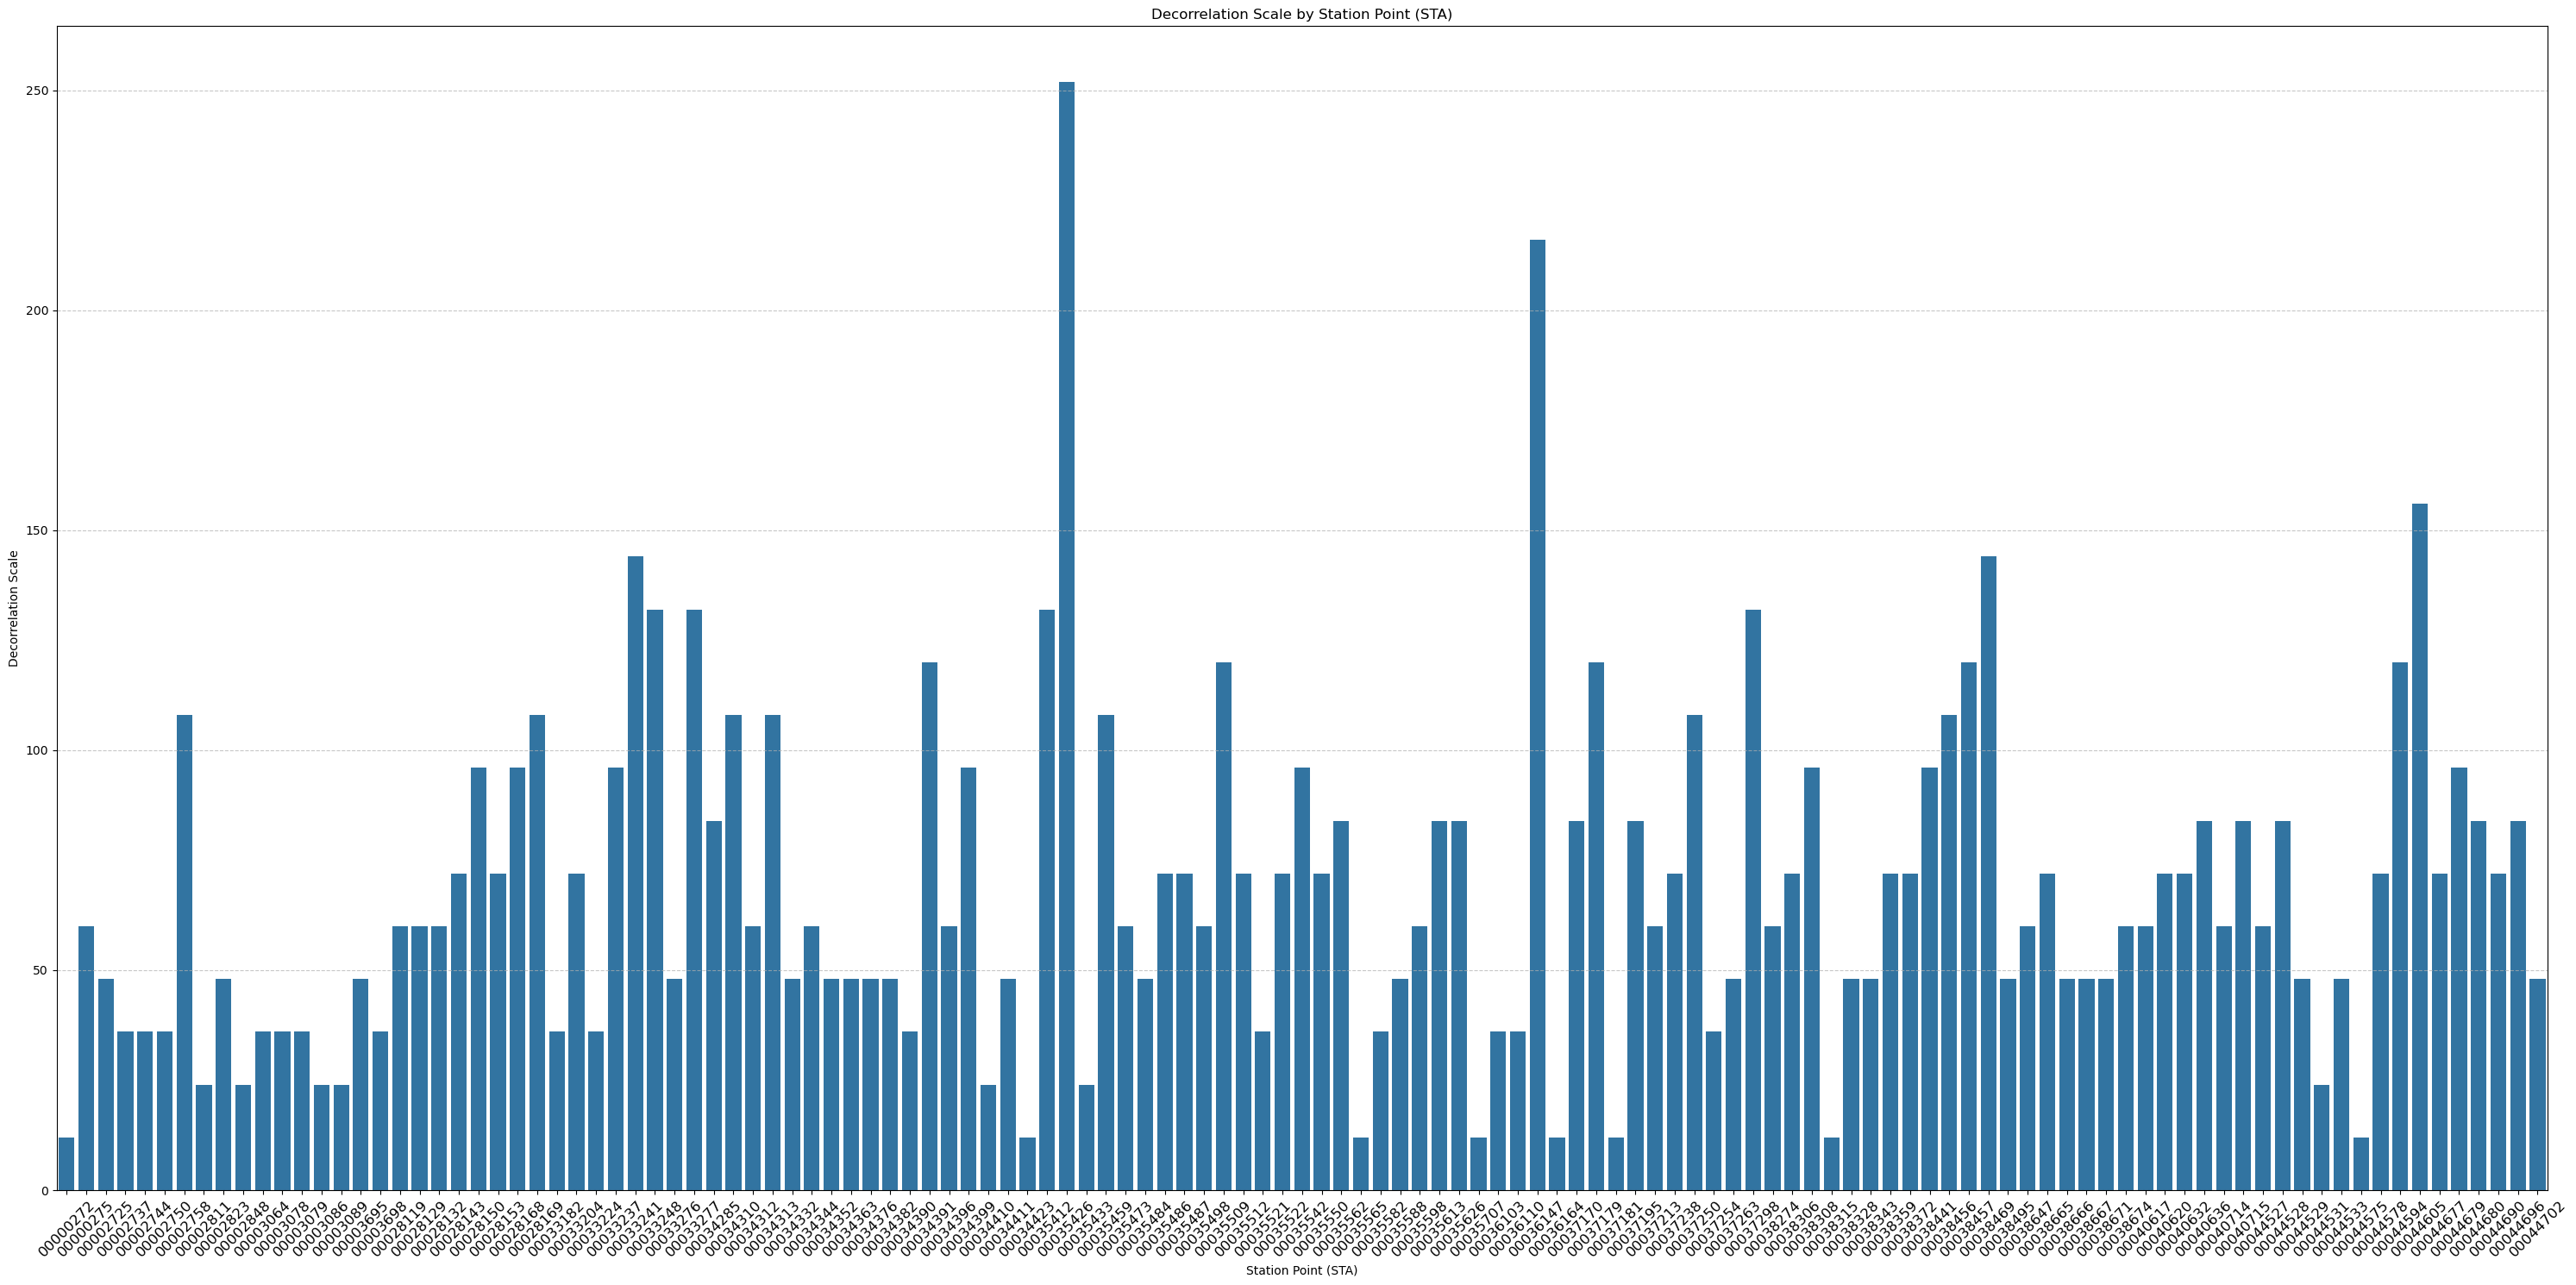

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plotting the decorrelation scale for each station point
plt.figure(figsize=(30, 15))
sns.barplot(data=decorrelation_results, x='Station_ID', y='Decorrelation_Scale_km')
plt.title('Decorrelation Scale by Station Point (STA)')
plt.xlabel('Station Point (STA)')
plt.ylabel('Decorrelation Scale')
plt.xticks(rotation=45, fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


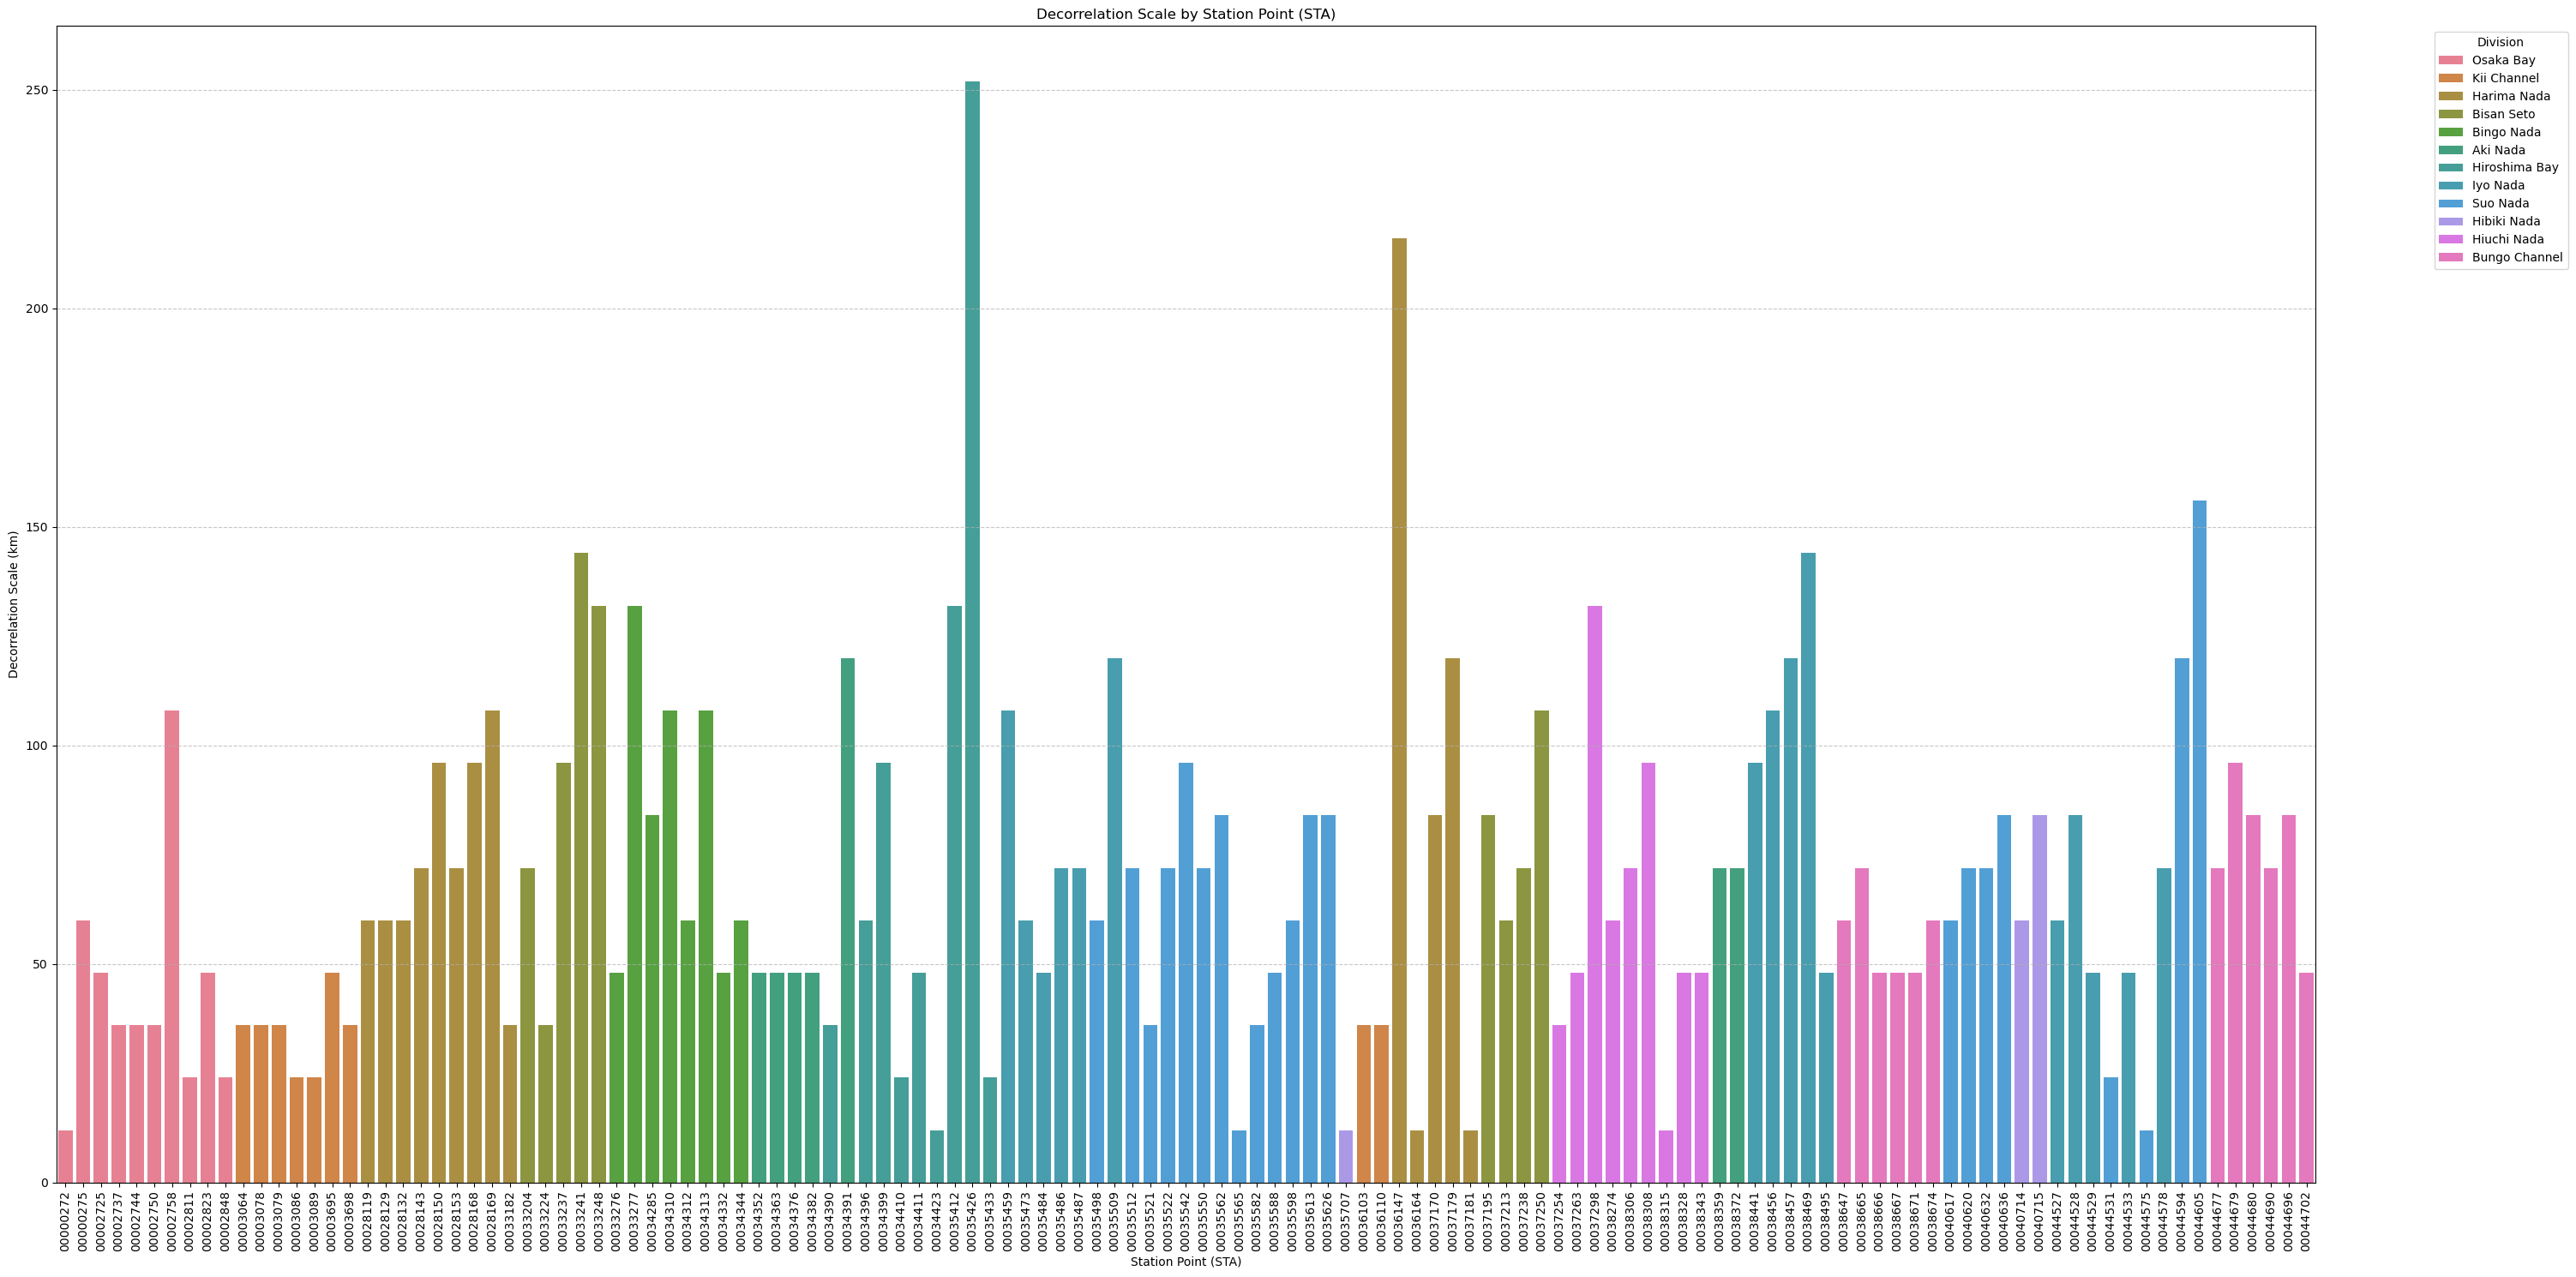

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

station_divisions = summer_bottom_df.groupby('zettaicode')['division'].first()
decorrelation_results['division'] = decorrelation_results['Station_ID'].map(station_divisions)

# Plotting
plt.figure(figsize=(30, 15))

# 2. Use 'hue' to color by division and 'dodge=False' to keep bars aligned
sns.barplot(
    data=decorrelation_results, 
    x='Station_ID', 
    y='Decorrelation_Scale_km', 
    hue='division',  # This assigns colors based on the division column
    dodge=False      # This prevents bars from getting thinner/offset
)

plt.title('Decorrelation Scale by Station Point (STA)')
plt.xlabel('Station Point (STA)')
plt.ylabel('Decorrelation Scale (km)')
plt.xticks(rotation=90, fontsize=10) # 90 degrees helps more with many stations
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title='Division', bbox_to_anchor=(1.05, 1), loc='upper left') # Move legend outside
plt.tight_layout()
plt.show()

Station ID 00035412 has the highest decorrelation scale value.

Now let's visualize the decorrelation scale value on the map.

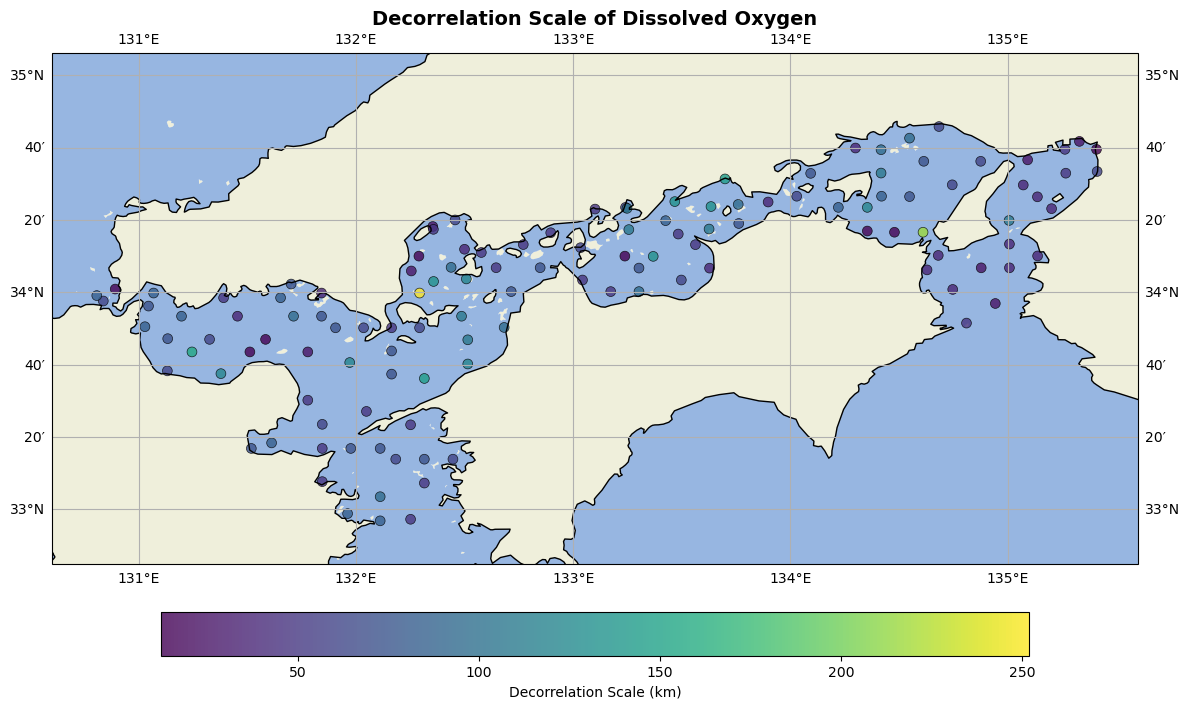

In [ ]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# --- 1. Map of Decorrelation Scale ---
fig = plt.figure(figsize=(12, 10))
ax = plt.axes(projection=ccrs.PlateCarree())
# Set extent for Seto Inland Sea
ax.set_extent([130.6, 135.6, 32.75, 35.1], crs=ccrs.PlateCarree())
# Add map features
ax.coastlines()
ax.add_feature(cfeature.LAND)
ax.add_feature(cfeature.OCEAN)
ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
# Plot points colored by Decorrelation Scale
sc = ax.scatter(
    results_df['Lon'], 
    results_df['Lat'], 
    c=results_df['Decorrelation_Scale_km'], 
    cmap='viridis', 
    s=50, 
    alpha=0.8,
    transform=ccrs.PlateCarree(),
    edgecolors='black',
    linewidth=0.5
)
# Add Colorbar
plt.colorbar(sc, ax=ax, label='Decorrelation Scale (km)', orientation='horizontal', pad=0.05, shrink=0.8)
ax.set_title('Decorrelation Scale of Dissolved Oxygen', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

This is the distribution map of decorrelation scale of each station points in the Seto Inland Sea. The calculation was done using 

C:\Users\reyha\AppData\Local\Temp\ipykernel_19692\2024508056.py:42: UserWarning: Adding colorbar to a different Figure <Figure size 1200x1000 with 2 Axes> than <Figure size 1200x1000 with 2 Axes> which fig.colorbar is called on.
  plt.colorbar(sc, ax=ax, label='Decorrelation Scale (km)', orientation='horizontal', pad=0.05, shrink=0.8)


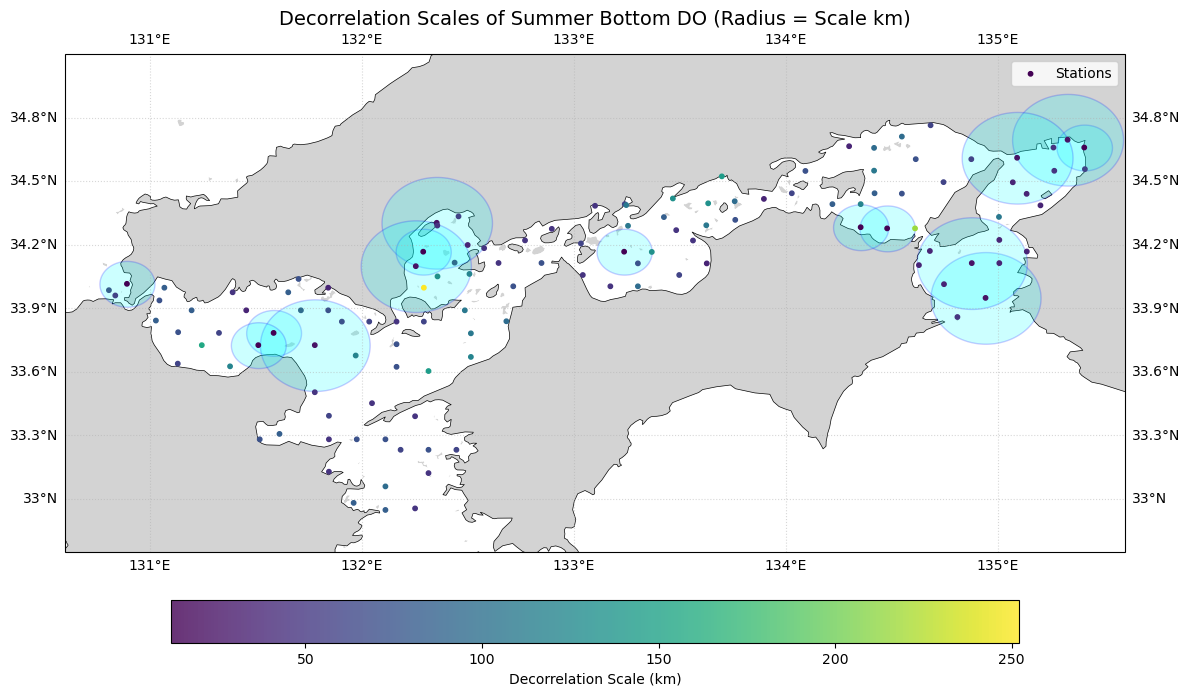

In [ ]:
from cartopy.geodesic import Geodesic
from shapely.geometry import Polygon

fig = plt.figure(figsize=(12, 10))
ax = plt.axes(projection=ccrs.PlateCarree())

# Set extent for Seto Inland Sea
ax.set_extent([130.6, 135.6, 32.75, 35.1], crs=ccrs.PlateCarree())

# Add map features
ax.add_feature(cfeature.LAND, facecolor='lightgray')
ax.add_feature(cfeature.OCEAN, facecolor='white')
ax.coastlines(resolution='10m', linewidth=0.5)
ax.gridlines(draw_labels=True, linestyle=':', alpha=0.5)

# Calculate and Plot Geodesic Circles
geod = Geodesic()

# Create a customized color map or logic if you want color to ALSO mean something, 
# but for now we color uniformly as requested, size is what matters.
# Using 'blue' with transparency.
for idx, row in results_df.iterrows():
    scale_km = row['Decorrelation_Scale_km']
    
    if pd.notnull(scale_km) and scale_km < 25: # filter out stations with no decorrelation scale or scale > 25 km
        # Geodesic.circle takes radius in meters
        radius_m = scale_km * 1000 
        
        # Generate points for the circle
        circle_points = geod.circle(lon=row['Lon'], lat=row['Lat'], radius=radius_m)
        
        # Create a Polygon from points
        circle_poly = Polygon(circle_points)
        
        # Add to ax as a geometry
        ax.add_geometries([circle_poly], crs=ccrs.PlateCarree(), 
                          facecolor='cyan', edgecolor='blue', alpha=0.2, linewidth=1)

# Overlay the station centers
ax.scatter(results_df['Lon'], results_df['Lat'], c=results_df['Decorrelation_Scale_km'], 
            cmap='viridis', s=10, transform=ccrs.PlateCarree(), zorder=10, label='Stations')
plt.colorbar(sc, ax=ax, label='Decorrelation Scale (km)', orientation='horizontal', pad=0.05, shrink=0.8)
ax.set_title(f'Decorrelation Scales of Summer Bottom DO (Radius = Scale km)', fontsize=14)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

This map visualize the area of influence of the stations that has the smallest decorrelation scale. I have set the threshold to 25 km. This map shows that the localized area are located in Osaka Bay, Kii Channel, Southern side of Harima Nada, Hiroshima Bay, Eastern Suo Nada, and Hibiki Nada.

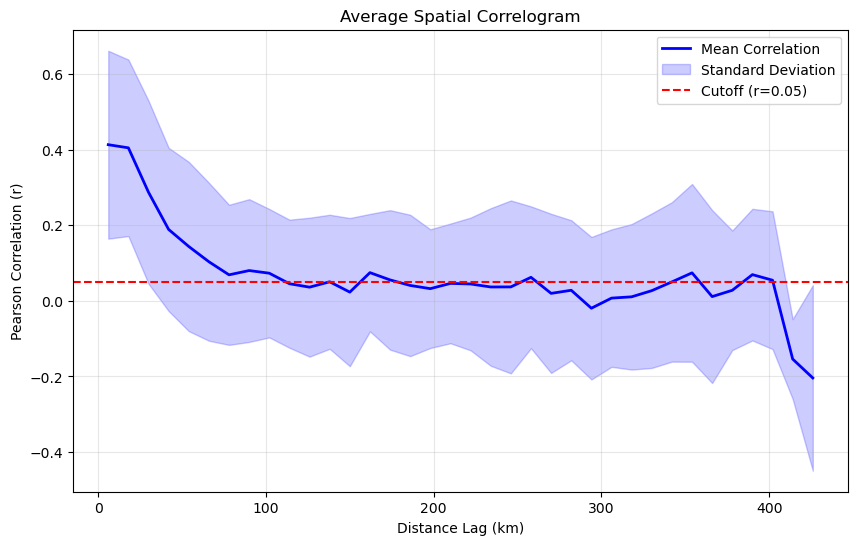

In [ ]:
# --- 3. Correlogram (Average Decay Curve) ---
plt.figure(figsize=(10, 6))
ax_corr = plt.gca()

# Collect all curve data
all_curves = []
for station_id, df in correlation_curves.items():
    if not df.empty:
        df['station_id'] = station_id
        all_curves.append(df)

if all_curves:
    combined_curves = pd.concat(all_curves)
    # Aggregate by distance bin
    agg_curve = combined_curves.groupby('distance')['correlation'].agg(['mean', 'std']).reset_index()
    
    ax_corr.plot(agg_curve['distance'], agg_curve['mean'], 'b-', linewidth=2, label='Mean Correlation')
    ax_corr.fill_between(
        agg_curve['distance'], 
        agg_curve['mean'] - agg_curve['std'], 
        agg_curve['mean'] + agg_curve['std'], 
        color='b', 
        alpha=0.2, 
        label='Standard Deviation'
    )
    
    ax_corr.axhline(CORR_CUTOFF, color='r', linestyle='--', label=f'Cutoff (r={CORR_CUTOFF})')
    ax_corr.set_title('Average Spatial Correlogram')
    ax_corr.set_xlabel('Distance Lag (km)')
    ax_corr.set_ylabel('Pearson Correlation (r)')
    ax_corr.legend()
    ax_corr.grid(True, alpha=0.3)
    
plt.show()

This is the average correlogram of all of the stations. Now let's try making a seperate plot for each station.

Prompt: create a code to continue the analysis from '07_Decorrelation_Analysis.ipynb'. Now I want to make a seperate correlogram plot for each station. Use the same variables that has been defined in this notebook. Save the resulting figures in a new folder named 'correlograms' in the FIGURES_DIR with the name 'correlogram_{station_id}.png'.